# Introduction

The dataset used in this excercise was `wolne_lektury_corpus` from Speakleash library. `prepare_dataset.py` downloads dataset, splits it into training and validation sets. 

The tokenizer of choice was Sentencepiece BPE with a vocabulary of `50257` tokens. It was trained on the training set of the `wolne_lektury_corpus` with `train_tokenizer.py`. 
The `train` and `validation` were tokenized before language model training and stored into files to optimize training process and precompute tokenized datasets (`encode_dataset.py`).

All experiments were run on:

- GPU: NVIDIA RTX 3060Ti 8GB VRAM
- RAM: 32GB DDR5
- CPU: AMD Ryzen 7 7800X3D

I have implemented RNN and LSTM models and Transformer model for comparison.
Additionally I have implemented few modern "twists" in the Transformer model architecture:

Comparison with GPT-2:
- RMSNorm instead of LayerNorm
- Rotary positional embeddings
- SwiGLU activation functions

I have also implemented weight initialization of transformer model with normal distribution.

In total I have 4 models to compare:
- RNN
- LSTM
- Transformer with learned Positional Embeddings and MLP
- Transformer with Rotary Positional Embeddings and SWiGLU

# Training

I have implemented two similar scripts for training the models: `train_rnn.py` and `train_transformer.py`. Both scripts loads precomputed data with `np.memmap` and uses `AdamW` optimizer for training. I have also added gradient clipping to value of `1.0` to prevent exploding gradients.

All models have been trained for `30000` steps with `BLOCK_SIZE` of `256`

### Training History

In [1]:
import json

history_paths = {
    "RNN": "checkpoints/rnn_sentencepiece_history.json",
    "LSTM": "checkpoints/lstm_sentencepiece_history.json",
    "Transformer + Learned + MLP": "checkpoints/transformer_learned_mlp_history.json",
    "Transformer + ROPE + SWiGLU": "checkpoints/transformer_rope_swiglu_history.json"
}

history_data = {}

for model_name, history_path in history_paths.items():
    with open(history_path, "r") as f:
        history = json.load(f)

    train_steps = []
    train_loss = []
    for entry in history["train"]:
        train_steps.append(entry["step"])
        train_loss.append(entry["loss"])

    val_steps = []
    val_loss = []
    for entry in history["validation"]:
        val_steps.append(entry["step"])
        val_loss.append(entry["loss"])

    history_data[model_name] = {
        "train_loss": train_loss,
        "train_steps": train_steps,
        "val_loss": val_loss,
        "val_steps": val_steps,
        "train_time": history["training_time_seconds"]
    }

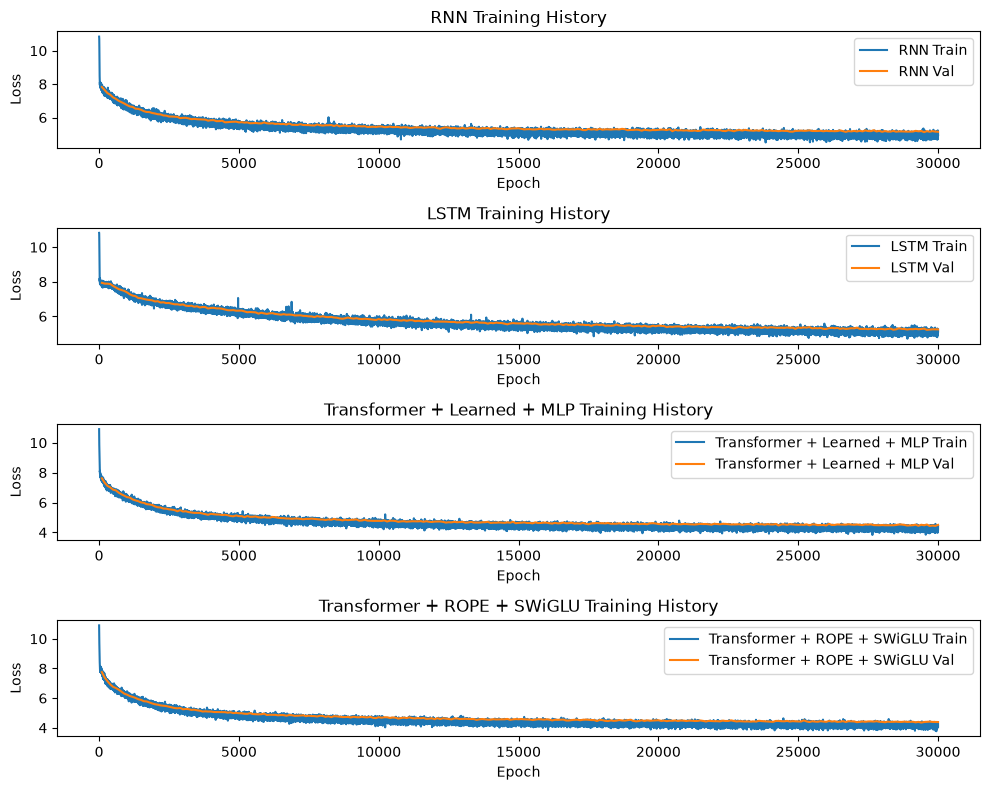

In [2]:
from matplotlib import pyplot as plt

fig, axs = plt.subplots(4, 1, figsize=(10, 8))

for i, (model_name, history) in enumerate(history_data.items()):
    axs[i].plot(history["train_steps"], history["train_loss"], label=f"{model_name} Train")
    axs[i].plot(history["val_steps"], history["val_loss"], label=f"{model_name} Val")
    axs[i].set_xlabel("Epoch")
    axs[i].set_ylabel("Loss")
    axs[i].set_title(f"{model_name} Training History")
    axs[i].legend()

plt.tight_layout()
plt.show()

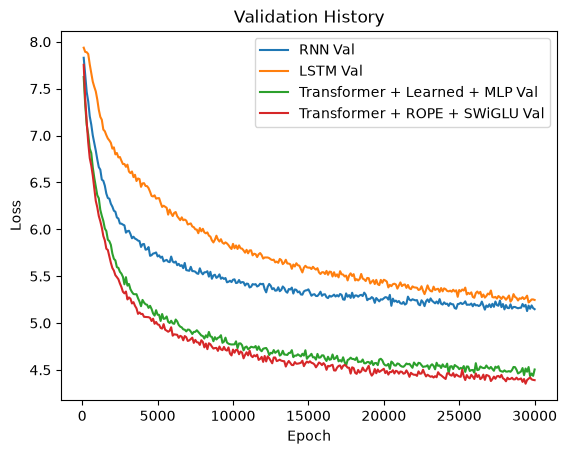

In [3]:
for model_name, history in history_data.items():
    plt.plot(history["val_steps"], history["val_loss"], label=f"{model_name} Val")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation History")
plt.legend()
plt.show()

RNN Training Time: 98.73 minutes
LSTM Training Time: 210.09 minutes
Transformer + Learned + MLP Training Time: 65.99 minutes
Transformer + ROPE + SWiGLU Training Time: 69.57 minutes


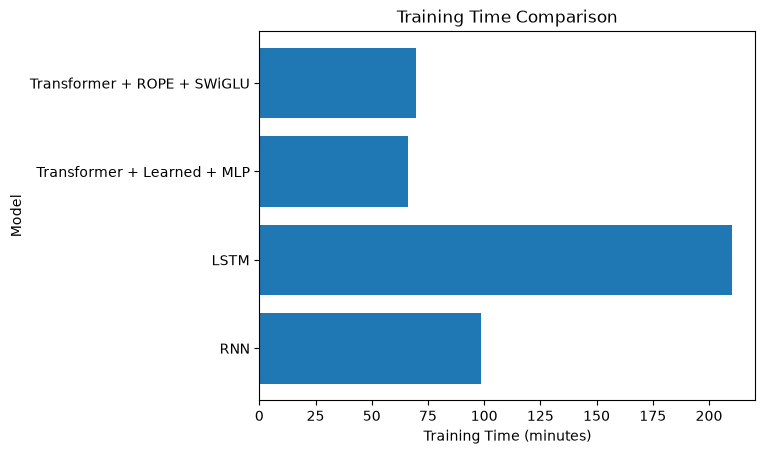

In [4]:
train_times = {model_name: history["train_time"] for model_name, history in history_data.items()}

for model_name, train_time in train_times.items():
    print(f"{model_name} Training Time: {train_time / 60:.2f} minutes")

plt.barh(train_times.keys(), [t / 60 for t in train_times.values()])
plt.xlabel("Training Time (minutes)")
plt.ylabel("Model")
plt.title("Training Time Comparison")
plt.show()

### Loading Models

In [5]:
import torch

from models.rnn import RNN, LSTM
from models.transformer import LanguageTransformer
from custom_tokenizers import SentencePieceBPETokenizer

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [7]:
def load_model(model_class, model_path, device):
    checkpoint = torch.load(
        model_path,
        map_location=device,
        weights_only=True,
    )

    model = model_class(**checkpoint["config"]).to(device)
    model.load_state_dict(checkpoint["model"])
    model.eval()
    return model, checkpoint["config"]

In [8]:
rnn_model, rnn_config = load_model(RNN, "checkpoints/rnn_sentencepiece.pt", device)
lstm_model, lstm_config = load_model(LSTM, "checkpoints/lstm_sentencepiece.pt", device)
transformer_model_learned_mlp, transformer_learned_mlp_config = load_model(LanguageTransformer, "checkpoints/transformer_learned_mlp.pt", device)
transformer_model_rope_swiglu, transformer_rope_swiglu_config = load_model(LanguageTransformer, "checkpoints/transformer_rope_swiglu.pt", device)

### Parameters

Each model were trained with following parameters:

In [9]:
rnn_config

{'vocab_size': 50257,
 'embedding_dim': 384,
 'hidden_size': 512,
 'num_layers': 2}

In [10]:
lstm_config

{'vocab_size': 50257,
 'embedding_dim': 384,
 'hidden_size': 512,
 'num_layers': 2}

In [11]:
transformer_learned_mlp_config

{'vocab_size': 50257,
 'dim': 384,
 'num_heads': 6,
 'ff_hidden_dim': 1536,
 'num_layers': 6,
 'block_size': 256,
 'feed_forward': 'mlp',
 'use_rope': False,
 'weight_tying': True}

In [12]:
transformer_rope_swiglu_config

{'vocab_size': 50257,
 'dim': 384,
 'num_heads': 6,
 'ff_hidden_dim': 1024,
 'num_layers': 6,
 'block_size': 256,
 'feed_forward': 'swiglu',
 'use_rope': True,
 'weight_tying': True}

Feed forward dimension for transfomers were chosen with the rule:
- for MLP, it was set to `4 * embedding_size`
- for SwiGLU, it was set to `8/3 * embedding_size`

In [13]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Model parameters count:

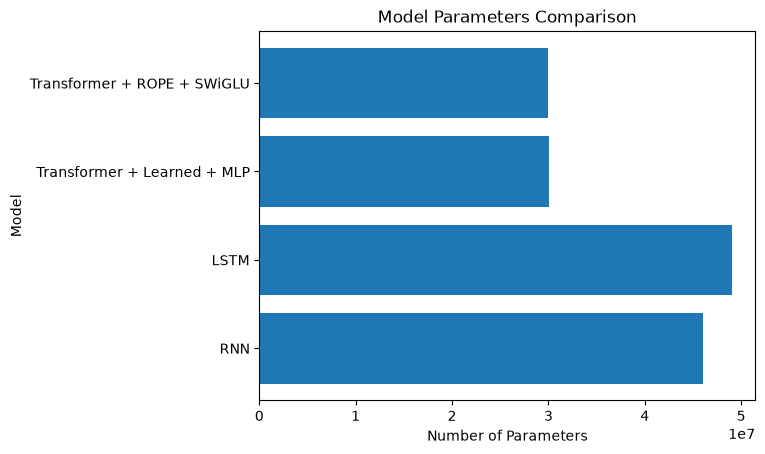

In [14]:
parameters_counts = {
    "RNN": count_parameters(rnn_model),
    "LSTM": count_parameters(lstm_model),
    "Transformer + Learned + MLP": count_parameters(transformer_model_learned_mlp),
    "Transformer + ROPE + SWiGLU": count_parameters(transformer_model_rope_swiglu)
}

plt.barh(list(parameters_counts.keys()), list(parameters_counts.values()))
plt.xlabel("Number of Parameters")
plt.ylabel("Model")
plt.title("Model Parameters Comparison")
plt.show()

Number of Parameters per Unit Time

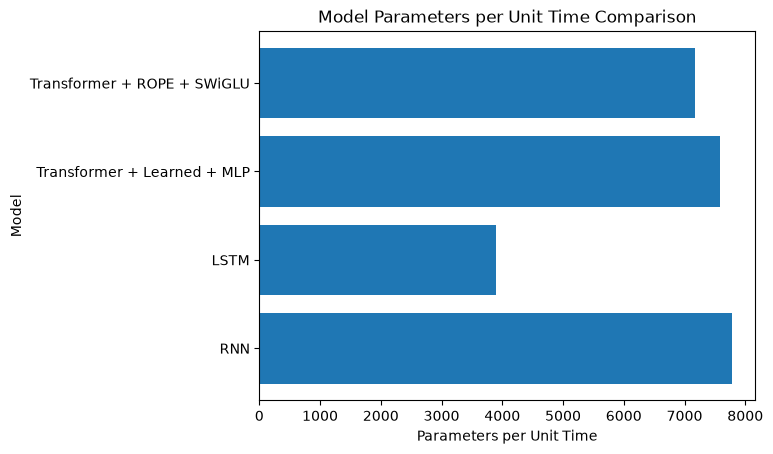

In [15]:
parameters_per_time = {k: v / train_times[k] for k, v in parameters_counts.items()}

plt.barh(list(parameters_per_time.keys()), list(parameters_per_time.values()))
plt.xlabel("Parameters per Unit Time")
plt.ylabel("Model")
plt.title("Model Parameters per Unit Time Comparison")
plt.show()

# Inference

Load the tokenizer

In [16]:
tokenizer = SentencePieceBPETokenizer()
tokenizer.load("output/sp_bpe.model")

Functions to generate text using 

In [17]:
@torch.inference_mode()
def generate(model, prompt, max_new_tokens=100, temperature=0.8):

    tokens = tokenizer.encode(prompt)
    x = torch.tensor([tokens], dtype=torch.long, device=device)

    state = None

    model_type = "transformer" if isinstance(model, LanguageTransformer) else "rnn"

    for _ in range(max_new_tokens):

        if model_type == "rnn":
            logits, state = model(x, state)
        else:
            logits = model(x[:, -model.block_size:])

        probabilities = torch.softmax(
            logits[:, -1, :] / temperature, dim=-1
        )

        next_token = torch.multinomial(probabilities, num_samples=1)
        tokens.append(next_token.item())

        if model_type == "rnn":
            x = next_token
        else:
            x = torch.cat([x, next_token], dim=1)

    return tokenizer.decode(tokens)

### Example prompts

In [18]:
print(generate(rnn_model, "Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu."))

Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu. Później ogarnęło je z jej strony. Ale dziewczynka, w której on ją objawiał sobie w głowie, nie było jej kroków, w chwili zaś, coś zabarwionego odtąd stawały się w dłoniach. — Niestety, — rzekłem — i nie wypuszczałem tu, jak się nam podoba — odparłem po prostu, na maszście. — Och, dziękuję, Boże! — zawołano wesoło. — Myślisz!... — zawołał pan Michałowi, bo się nie boję


In [19]:
print(generate(lstm_model, "Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu."))

Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu. Czuję teraz, że nie mógł widzieć małą siostrzeniec przy stole. Wstał z rogu i zapytał, że wcale nie wiemy o tym, że z wolna obecni zdarzenia nie mając jej ich zatrzymać. Widziałam sobie, że są u nich, abym zawsze miał rację, to czyniła. Mam dwadzieścia rubli czynnych takich powodów! — To znaczy ci pieczęć i prawie myśli — czyniąc tuż z wojskiem?... — Co? — zapytał i schylił się,


In [20]:
print(generate(transformer_model_learned_mlp, "Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu."))

Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu. — Jestem tak bardzo bogata, że to niemożliwe, ażeby mi to dostać do domu. — Ale ja muszę przecież wyjechać. Pierwszy raz powiedziała do męża: — Czy i mnie nie jest kochanką, że nie byłem szczęśliwy? — Nie. — Nie odrzekła. — Nie waham się. — No, nie mogę, nie! — A może to jest zanadto bardzo miły Winkret? — I tak sobie — odpowiedział smutnie. — Od panią nigdy nie miałam ani na chwilę


In [21]:
print(generate(transformer_model_rope_swiglu, "Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu."))

Pewnego dnia młoda kobieta wyszła z domu i poszła do ogrodu. — Aha! — rzekła do siebie — nikt o tym nie myśli. — Naturalnie! — zawołał Eugeniusz. — Czy ci to dobrze? — spytał. — Powiem ci prawdę. — A więc proszę mnie o to, czy jest ktoś podobnym do Messiena, którego wcale nie widziałam? — Nie! — odparł Eugeniusz. — Nie! — odparł Eugeniusz, bardzo surowym tonem. — Jest to już przecież istniejsza


### Perplexity

In [22]:
models = {
    "RNN": rnn_model,
    "LSTM": lstm_model,
    "Transformer + Learned + MLP": transformer_model_learned_mlp,
    "Transformer + RoPE + SwiGLU": transformer_model_rope_swiglu,
}

BLOCK_SIZE = 256
BATCH_SIZE = 8

Encode the test set

In [23]:
from pathlib import Path

text = Path("corpus/test.txt").read_text(encoding="utf-8")
test_ids = torch.tensor(tokenizer.encode(text), dtype=torch.long)

Add offset to ids to create labels:

In [24]:
tokens_count = ((len(test_ids) - 1) // BLOCK_SIZE) * BLOCK_SIZE

x = test_ids[:tokens_count].reshape(-1, BLOCK_SIZE)
y = test_ids[1:tokens_count + 1].reshape(-1, BLOCK_SIZE)

Create test batches (we ignore the last incomplete batch)

In [25]:
test_batches = [
    (x[i:i + BATCH_SIZE], y[i:i + BATCH_SIZE])
    for i in range(0, len(x), BATCH_SIZE)
]

In [26]:
num_tokens = sum(y.numel() for _, y in test_batches)
print(f"Number of tokens in test batches: {num_tokens}")

Number of tokens in test batches: 2800640


Define the perplexity function: 
$$
\text{PPL} = \exp\left(\frac{1}{N} \sum_{i=1}^{N} -\log p(y_i \mid x_i)\right)
$$

In [27]:
import math
import torch.nn.functional as F
from tqdm import tqdm

def get_logits(model, x):
    if isinstance(model, LanguageTransformer):
        return model(x)
    return model(x)[0]

@torch.inference_mode()
def token_perplexity(model):
    model.eval()
    total_nll = torch.zeros((), dtype=torch.float64, device=device)

    for x, y in tqdm(test_batches):
        x = x.to(device)
        y = y.to(device)

        logits = get_logits(model, x)
        total_nll += F.cross_entropy(
            logits.flatten(0, 1),
            y.flatten(),
            reduction="sum",
        ).double()
        del logits

    return math.exp(total_nll.item() / num_tokens)

100%|██████████| 1368/1368 [00:38<00:00, 36.00it/s]

RNN                                 PPL: 180.317
LSTM                                PPL: 198.041
Transformer + Learned + MLP         PPL: 94.472
Transformer + RoPE + SwiGLU         PPL: 85.103


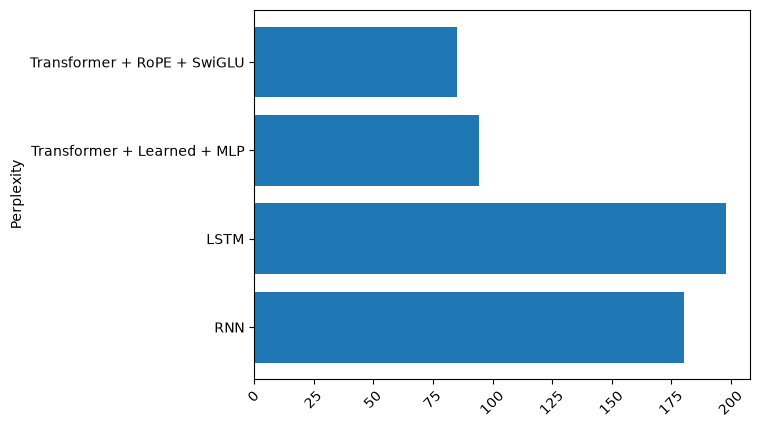

In [28]:
perplexities = {
    name: token_perplexity(model)
    for name, model in models.items()
}

for name, ppl in perplexities.items():
    print(f"{name:35s} PPL: {ppl:.3f}")

plt.barh(perplexities.keys(), perplexities.values())
plt.ylabel("Perplexity")
plt.xticks(rotation=45)
plt.show()

### Performance

Now lets measure how speed is inference of each token "token/second" for each model.

In [29]:
from time import perf_counter

def synchronize():
    if torch.device(device).type == "cuda":
        torch.cuda.synchronize(device)


@torch.inference_mode()
def benchmark(model):
    model.eval()

    warmup_x = test_batches[0][0].to(device)
    for _ in range(3):
        logits = get_logits(model, warmup_x)
        del logits

    synchronize()
    start = perf_counter()

    for x, _ in tqdm(test_batches):
        logits = get_logits(model, x.to(device))
        del logits

    synchronize()
    elapsed = perf_counter() - start

    return elapsed, num_tokens / elapsed

In [30]:
performances = {} 

for name, model in models.items():
    seconds, tokens_per_second = benchmark(model)
    performances[name] = (seconds, tokens_per_second)
    print(
        f"{name:35s} "
        f"{seconds:8.2f} s | {tokens_per_second:12,.0f} tokenów/s"
    )

100%|██████████| 1368/1368 [00:52<00:00, 25.86it/s]


RNN                                    52.92 s |       52,925 tokenów/s


100%|██████████| 1368/1368 [02:15<00:00, 10.10it/s]


LSTM                                  135.45 s |       20,677 tokenów/s


100%|██████████| 1368/1368 [00:29<00:00, 46.28it/s]


Transformer + Learned + MLP            29.57 s |       94,713 tokenów/s


100%|██████████| 1368/1368 [00:32<00:00, 41.92it/s]

Transformer + RoPE + SwiGLU            32.64 s |       85,808 tokenów/s


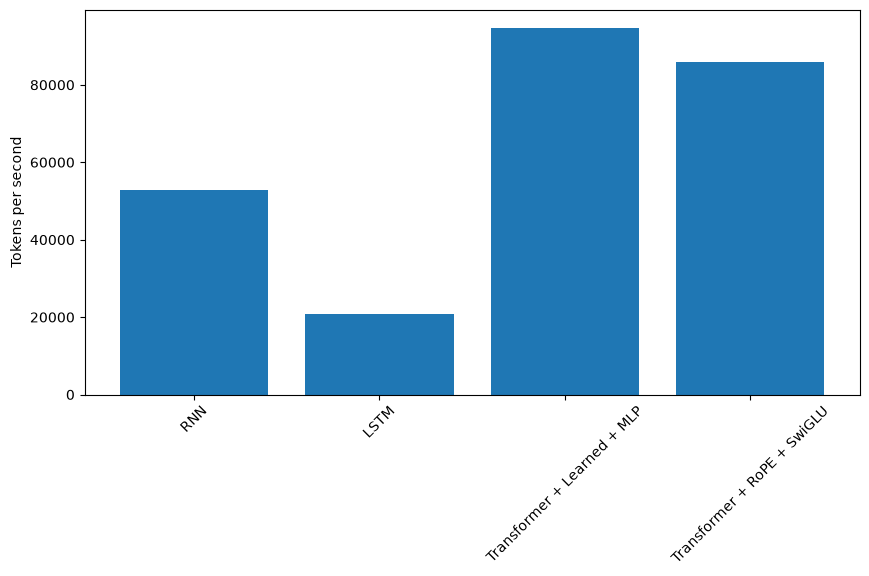

In [31]:
plt.figure(figsize=(10, 5))
plt.bar(performances.keys(), [x[1] for x in performances.values()])
plt.ylabel("Tokens per second")
plt.xticks(rotation=45)
plt.show()